# 09 – Seuil de coût du classifieur : quand déclencher l'alerte ?

**Question métier :** le classifieur XGBoost (`03b`) donne une probabilité de « panne dans 48 h ». À partir de quelle probabilité faut-il **intervenir** ? Le seuil par défaut (0,5) n'a aucune raison d'être le meilleur : rater une panne coûte bien plus cher qu'une intervention préventive.

**Méthode (même critère que `07_etude_cout`, pour que les résultats soient comparables) :**
- mêmes **hypothèses de coût** (MAD), mêmes **machines de test**, même fonction `evaluate()` ;
- alarme = **3 mesures consécutives** au-dessus du seuil (comme pour les anomalies) ;
- le seuil est choisi sur des machines de **calibration** (`cal`), puis évalué sur des machines de **test** jamais vues.

**Point important :** le modèle de `03b` a été entraîné sur toutes les machines d'entraînement, y compris celles de calibration. Choisir le seuil sur des machines que le modèle a déjà vues serait trop optimiste. On **réentraîne donc XGBoost (mêmes paramètres que `03b`) sur les seules machines `fit`**, exactement comme `04` et `07` le font pour leurs modèles.

**Entrées :** `features_temporal.csv`, `survival.csv`, `maintenance_log.csv`, `machines.csv` et `reports/tables/resultats_cout.csv` (créé par `07_etude_cout`).
**Sorties :** `reports/tables/resultats_cout_classifieur.csv`, `reports/figures/cout_seuil_classifieur.png`, `cout_politiques_classifieur.png`.

Données **synthétiques** et coûts **illustratifs** : le classement des politiques est une démonstration de méthode, pas un chiffrage pour une vraie usine.

## 1. Chargement

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "features.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from features import split_by_machine, SENSOR_COLS

(ROOT / "reports/figures").mkdir(parents=True, exist_ok=True)
(ROOT / "reports/tables").mkdir(parents=True, exist_ok=True)
SEED, CONSEC, HOURS_PER_YEAR = 42, 3, 8000        # mêmes constantes que 07
print("xgboost", xgboost.__version__)

res07 = ROOT / "reports/tables/resultats_cout.csv"
if not res07.exists():
    raise FileNotFoundError("resultats_cout.csv introuvable : lance d'abord 07_etude_cout.ipynb.")

xgboost 3.2.0


## 2. Hypothèses de coût (identiques à `07`)

`C_panne` = coût total d'une panne (réparation + production perdue pendant l'arrêt) ; `C_prev` = coût total d'une intervention préventive.

In [2]:
HYP = pd.DataFrame({
    "perte_prod_par_h":      {"broyeur": 30000, "ventilateur": 20000, "compresseur": 8000},
    "reparation_corrective": {"broyeur": 150000, "ventilateur": 60000, "compresseur": 40000},
    "cout_preventive":       {"broyeur": 20000,  "ventilateur": 8000,  "compresseur": 5000},
}).rename_axis("type")

log = pd.read_csv(ROOT / "data/synthetic/maintenance_log.csv").merge(
    pd.read_csv(ROOT / "data/synthetic/machines.csv"), on="machine_id")
arret = log.groupby(["machine_type", "type"]).downtime_h.mean().unstack()
HYP["arret_panne_h"] = arret["corrective"]
HYP["arret_preventive_h"] = arret["preventive"] if "preventive" in arret else 8.0
HYP["arret_preventive_h"] = HYP["arret_preventive_h"].fillna(8.0)

HYP["C_panne"] = HYP.reparation_corrective + HYP.perte_prod_par_h * HYP.arret_panne_h
HYP["C_prev"] = HYP.cout_preventive + HYP.perte_prod_par_h * HYP.arret_preventive_h
C = HYP[["C_panne", "C_prev"]]
HYP[["C_panne", "C_prev"]].round(0)

,C_panne,C_prev
type,,
broyeur,1533491.0,260000.0
ventilateur,961740.0,168000.0
compresseur,409858.0,69000.0


## 3. Données, découpage par machine et classifieur

Même découpage que `03b`, `04` et `07` : `test` (machines jamais vues), puis dans le reste, `fit` (entraînement) et `cal` (choix du seuil).

In [3]:
df = pd.read_csv(ROOT / "data/processed/features_temporal.csv")
sv = pd.read_csv(ROOT / "data/synthetic/survival.csv")
sv = sv[sv.duration_h > 0]

train, test = split_by_machine(df, test_size=0.25, seed=SEED)
fit, cal = split_by_machine(train, test_size=0.2, seed=SEED)
cyc = {name: sv[sv.machine_id.isin(d.machine_id.unique())].copy()
       for name, d in [("cal", cal), ("test", test)]}
print("machines fit / cal / test :", fit.machine_id.nunique(), "/", cal.machine_id.nunique(), "/", test.machine_id.nunique())

# mêmes variables que 03b (capteurs + features glissantes)
FEATURES = [c for c in df.columns if any(c.startswith(s) for s in SENSOR_COLS)]
y_fit = fit["failure_within_h"]
ratio = (y_fit == 0).sum() / (y_fit == 1).sum()

# mêmes paramètres que 03b, mais entraîné sur `fit` seulement
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                    colsample_bytree=0.8, scale_pos_weight=ratio, eval_metric="aucpr",
                    random_state=SEED, n_jobs=-1)
xgb.fit(fit[FEATURES], y_fit)

for d in (cal, test):
    d["score"] = xgb.predict_proba(d[FEATURES])[:, 1]     # probabilité de « panne dans 48 h »
print("scores calculés (probabilités)")

machines fit / cal / test : 36 / 9 / 15
scores calculés (probabilités)


## 4. Outils de simulation (identiques à `07`)

Chaque politique est évaluée sur les **cycles de vie historiques** : pour un cycle qui a duré `d` heures, on regarde ce que la politique aurait fait. `coût par heure = somme des coûts / somme des heures de fonctionnement`.

In [4]:
def first_alarm_age(d, thr):
    """Âge de la première alarme par cycle (alarme = CONSEC mesures consécutives > seuil)."""
    d = d.sort_values(["machine_id", "cycle_id", "time_h"])
    above = (d.score > thr).astype(int)
    alarm = above.groupby([d.machine_id, d.cycle_id]).transform(
        lambda s: s.rolling(CONSEC).min()).fillna(0).astype(bool)
    return d[alarm].groupby(["machine_id", "cycle_id"]).age_h.min().rename("alarm_age")

def evaluate(cycles, C, policy, T_star=None, alarm_age=None):
    """Retourne (coût total, heures) d'une politique sur un tableau de cycles."""
    c = cycles.join(C, on="machine_type")
    d, ev = c.duration_h.values, c.event.values.astype(bool)
    if policy == "corrective":
        stop, t_stop = np.zeros(len(c), bool), d
    elif policy == "ideale":
        cost = np.where(ev, c.C_prev, 0.0)
        return cost.sum(), d.sum()
    elif policy == "fixe":
        T = c.machine_type.map(T_star).values
        stop, t_stop = d > T, np.minimum(d, T)
    elif policy == "alarme":
        a = c.join(alarm_age, on=["machine_id", "cycle_id"]).alarm_age.values
        stop = ~np.isnan(a) & (a < d)
        t_stop = np.where(stop, a, d)
    cost = np.where(stop, c.C_prev, np.where(ev, c.C_panne, 0.0))
    return cost.sum(), t_stop.sum()

def rate(cycles, C, **kw):
    cost, hours = evaluate(cycles, C, **kw)
    return cost / hours        # MAD par heure de fonctionnement

# Vérification : on retrouve bien le coût « corrective » de 07 (mêmes machines de test, mêmes coûts)
ref = pd.read_csv(res07, index_col=0)
corr_07 = ref.loc[ref.index.str.startswith("Corrective"), "MAD/h"].iloc[0]
corr_ici = rate(cyc["test"], C, policy="corrective")
print(f"Corrective : {corr_ici:.2f} MAD/h ici, {corr_07:.2f} MAD/h dans 07")
assert abs(corr_ici - corr_07) / corr_07 < 1e-3, "Données ou découpage différents de 07 : lance d'abord python src/generate_data.py puis 07."

Corrective : 457.10 MAD/h ici, 457.10 MAD/h dans 07


## 5. Choix du seuil **par le coût**

On teste plusieurs seuils de probabilité et on garde celui qui **minimise le coût sur les machines de calibration**. Seuil bas = beaucoup d'alarmes (interventions inutiles) ; seuil haut = on rate des pannes. Le seuil par défaut 0,5 est affiché pour comparaison.

⚠️ Il y a peu de machines de calibration : le choix du seuil est un peu bruité, d'où l'importance de regarder la courbe du test.

In [5]:
SEUILS = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
rows = []
for thr in SEUILS:
    rows.append({"seuil": thr,
                 "coût/h calibration": rate(cyc["cal"], C, policy="alarme", alarm_age=first_alarm_age(cal, thr)),
                 "coût/h test": rate(cyc["test"], C, policy="alarme", alarm_age=first_alarm_age(test, thr))})
sweep = pd.DataFrame(rows).set_index("seuil")
thr_star = sweep["coût/h calibration"].idxmin()
print(f"Seuil choisi sur la calibration : {thr_star}  (au lieu de 0,5)")
sweep.round(1)

Seuil choisi sur la calibration : 0.8  (au lieu de 0,5)


,coût/h calibration,coût/h test
seuil,,
0.05,64.6,80.2
0.10,64.5,80.0
0.20,64.3,79.7
0.30,64.2,79.6
0.40,64.0,79.5
0.50,63.9,79.4
0.60,63.8,79.3
0.70,63.7,79.3
0.80,63.6,79.2


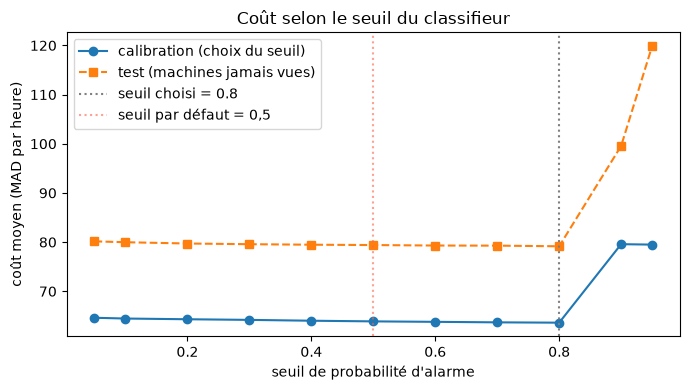

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep.index, sweep["coût/h calibration"], "o-", label="calibration (choix du seuil)")
ax.plot(sweep.index, sweep["coût/h test"], "s--", label="test (machines jamais vues)")
ax.axvline(thr_star, color="gray", ls=":", label=f"seuil choisi = {thr_star}")
ax.axvline(0.5, color="tomato", ls=":", alpha=.6, label="seuil par défaut = 0,5")
ax.set_xlabel("seuil de probabilité d'alarme"); ax.set_ylabel("coût moyen (MAD par heure)")
ax.set_title("Coût selon le seuil du classifieur"); ax.legend()
plt.tight_layout(); plt.savefig(ROOT / "reports/figures/cout_seuil_classifieur.png", dpi=150); plt.show()

## 6. Que se passe-t-il concrètement avec ce seuil ? (machines de test)

- **Taux de détection** : part des pannes précédées d'une alarme.
- **Délai d'anticipation** : heures entre la 1ʳᵉ alarme et la panne.
- **Interventions inutiles** : part des cycles qui se terminent **sans panne** mais où une alarme a quand même déclenché une intervention.

In [7]:
def bilan(thr):
    a = first_alarm_age(test, thr)
    c = cyc["test"].join(a, on=["machine_id", "cycle_id"])
    alarme = c.alarm_age < c.duration_h
    pannes, sans = c[c.event == 1], c[c.event == 0]
    return {"seuil": thr,
            "pannes détectées": f"{(alarme & (c.event == 1)).sum()} / {len(pannes)}",
            "délai moyen d'anticipation (h)": round((pannes.duration_h - pannes.alarm_age)[alarme[pannes.index]].mean(), 0),
            "interventions inutiles": f"{(alarme & (c.event == 0)).sum()} / {len(sans)}"}

pd.DataFrame([bilan(0.5), bilan(thr_star)]).set_index("seuil")

,pannes détectées,délai moyen d'anticipation (h),interventions inutiles
seuil,,,
0.5,44 / 44,51.0,0 / 14
0.8,44 / 44,43.0,0 / 14


## 7. Comparaison avec les autres politiques

Les lignes corrective, âge fixe, alarme anomalies et idéale viennent de `07_etude_cout` (mêmes machines de test, mêmes coûts, même `evaluate()`). On ajoute le classifieur avec le seuil par défaut puis avec le seuil choisi par le coût.

In [8]:
res = ref["MAD/h"].copy()
res["Prédictive (classifieur, seuil 0,5)"] = rate(cyc["test"], C, policy="alarme", alarm_age=first_alarm_age(test, 0.5))
res[f"Prédictive (classifieur, seuil coût = {thr_star})"] = rate(cyc["test"], C, policy="alarme", alarm_age=first_alarm_age(test, thr_star))

# ordre d'affichage : du plus cher au moins cher
res = res.sort_values(ascending=False)
corr = res[res.index.str.startswith("Corrective")].iloc[0]
final = res.to_frame("MAD/h")
final["MAD/an/machine"] = (res * HOURS_PER_YEAR).round(-3)
final["économie vs corrective"] = (1 - res / corr).map("{:.0%}".format)
final.to_csv(ROOT / "reports/tables/resultats_cout_classifieur.csv")
final.round(0)

,MAD/h,MAD/an/machine,économie vs corrective
Corrective (attendre la panne),457.0,3657000.0,0%
Préventive à âge fixe,298.0,2383000.0,35%
Prédictive (alarme anomalies),106.0,850000.0,77%
"Prédictive (classifieur, seuil 0,5)",79.0,635000.0,83%
"Prédictive (classifieur, seuil coût = 0.8)",79.0,633000.0,83%
Idéale (limite théorique),78.0,623000.0,83%


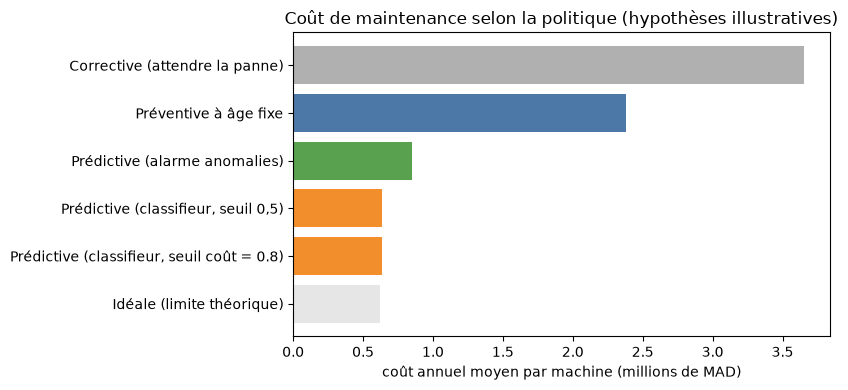

In [9]:
couleurs = ["#e6e6e6" if "Idéale" in k else "#b0b0b0" if "Corrective" in k else "#4c78a8" if "fixe" in k
            else "#59a14f" if "anomalies" in k else "#f28e2b" for k in res.index]
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh(list(res.index)[::-1], (res * HOURS_PER_YEAR / 1e6).values[::-1], color=couleurs[::-1])
ax.set_xlabel("coût annuel moyen par machine (millions de MAD)")
ax.set_title("Coût de maintenance selon la politique (hypothèses illustratives)")
plt.tight_layout(); plt.savefig(ROOT / "reports/figures/cout_politiques_classifieur.png", dpi=150); plt.show()

## À retenir pour le rapport

- Compléter ici : le **seuil choisi** par le coût et le **gain** par rapport au seuil 0,5 (§5 et §7) ; le classement final des politiques, et si le classifieur fait mieux ou moins bien que l'alarme par anomalies.
- Le seuil optimal est souvent **plus bas que 0,5** quand une panne coûte bien plus cher qu'une intervention préventive : on accepte quelques interventions inutiles pour ne pas rater de pannes.
- Un classifieur est **supervisé** (il a besoin d'étiquettes « panne dans 48 h »), alors que l'alarme par anomalies n'en a pas besoin : à comparer dans `06_comparaison`.
- Limites : peu de machines de calibration (seuil bruité), données **synthétiques**, coûts **illustratifs**.